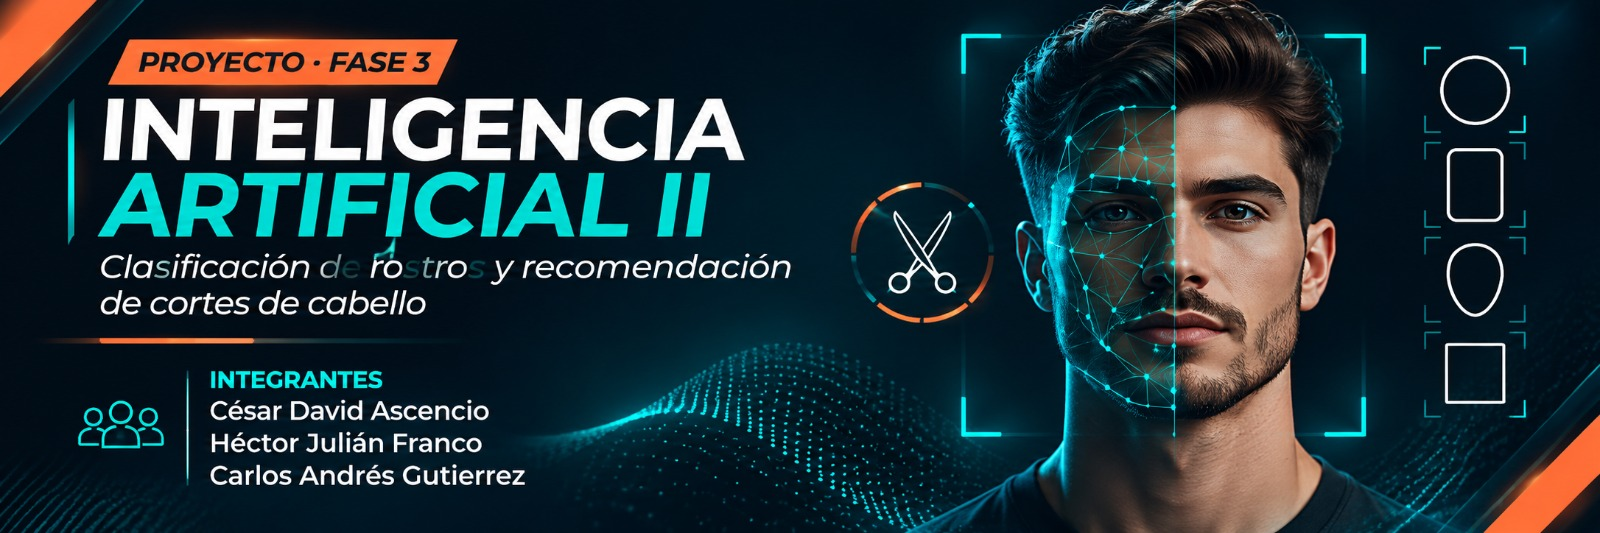

# **Proyecto de Inteligencia Artificial II · Fase 3**

Este notebook clasifica la forma del rostro de un hombre (**Redondo, Rectangular, Ovalado o Cuadrado**) y, con base en ella, recomienda **1 o 2 cortes de cabello, el largo superior y un ranking de 3 degradados**, como base para una barbería.

**Cómo funciona:** MTCNN detecta el rostro, MediaPipe ubica 5 puntos faciales para recortarlo sin deformarlo, un ensamble de 3 modelos FaceNet (entrenados con Softmax + Center Loss) predice la forma, y un motor de reglas basado en guías de barberos convierte esa forma en la recomendación.

**Datos:** 1270 imágenes de entrenamiento y 323 de prueba, balanceadas entre las 4 clases.

**Resultado:** 70.0% de accuracy en Test. Los cortes recomendados coinciden con los etiquetados en 73.4% (corte principal) y 87.9% (al menos un corte válido). Las clases más confundidas son Rectangular y Ovalado.

---
## 1. Configuración

### 1.1 Conectar Google Drive

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


### 1.2 Instalar MTCNN y MediaPipe

`mtcnn` es el detector de rostros. `mediapipe` aporta los puntos faciales extra que MTCNN no puede dar (solo entrega 5 puntos: ojos, nariz y boca). El `wget` descarga el archivo `face_landmarker.task`, el modelo que MediaPipe necesita. Si Colab pide reiniciar el entorno después de instalar, hay que volver a correr la sección 1.1.

In [2]:
!pip install mtcnn mediapipe -q
!wget -q -O face_landmarker.task https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task

### 1.3 Rutas, clases y conteo de imágenes

Define las carpetas de `Train` y `Test` y las 4 clases (el nombre de cada subcarpeta es la etiqueta de sus imágenes), y cuenta cuántas imágenes hay por clase.

**Resultado:** 1270 imágenes en Train y 323 en Test, con las clases bien balanceadas.

In [3]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

RUTA_TRAIN = '/content/drive/MyDrive/Proyecto IA II/Dataset - Rostros Masculinos/Train'
RUTA_TEST = '/content/drive/MyDrive/Proyecto IA II/Dataset - Rostros Masculinos/Test'



clases = ['Redondo', 'Rectangular', 'Ovalado', 'Cuadrado']
extensiones = ('.jpg', '.jpeg', '.png')

for nombre_set, ruta_set in [('Train', RUTA_TRAIN), ('Test', RUTA_TEST)]:
    print(nombre_set)
    total = 0
    for c in clases:
        carpeta = os.path.join(ruta_set, c)
        n = len([f for f in os.listdir(carpeta) if f.lower().endswith(extensiones)])
        total += n
        print('  ', c, ':', n)
    print('  Total:', total)

Train
   Redondo : 322
   Rectangular : 312
   Ovalado : 313
   Cuadrado : 323
  Total: 1270
Test
   Redondo : 83
   Rectangular : 81
   Ovalado : 81
   Cuadrado : 78
  Total: 323


---
## 2. Detección de rostros y puntos faciales

### 2.1 MTCNN: detección del rostro

MTCNN son tres redes en cascada (P-Net propone zonas, R-Net las refina y O-Net da el cuadro final y 5 puntos). Para cada rostro entrega el cuadro (`box`, en formato `[x, y, ancho, alto]`), la confianza y 5 puntos. Aquí se prueba en una imagen por clase: el cuadro verde es el rostro encontrado. El cuadro de MTCNN es ajustado y deja la frente fuera, y por eso más adelante se amplía.

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


Redondo -> confianza: 0.994
Rectangular -> confianza: 0.997
Ovalado -> confianza: 0.948
Cuadrado -> confianza: 0.999


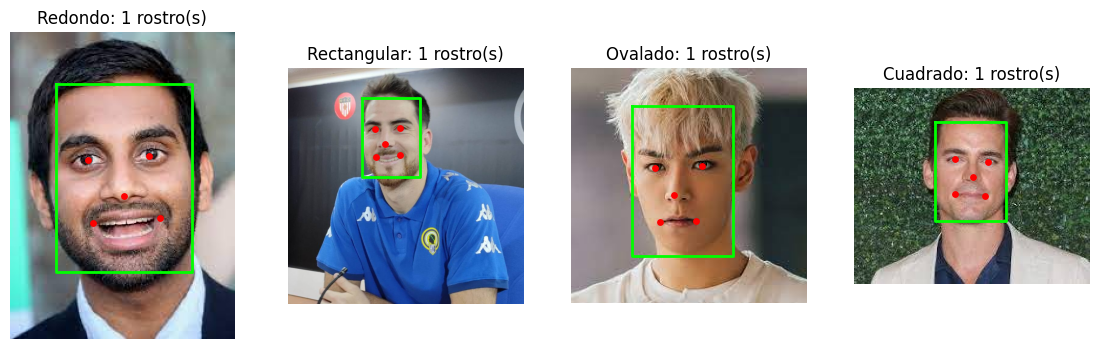

In [4]:
from mtcnn import MTCNN

detector = MTCNN(device='CPU:0')

plt.figure(figsize=(14, 4))
for i, nombre in enumerate(clases):
    carpeta = os.path.join(RUTA_TRAIN, nombre)
    archivos = [f for f in os.listdir(carpeta) if f.lower().endswith(extensiones)]
    elegido = random.choice(archivos)
    arreglo = np.array(Image.open(os.path.join(carpeta, elegido)).convert('RGB'))
    resultados = detector.detect_faces(arreglo)

    plt.subplot(1, 4, i + 1)
    plt.imshow(arreglo)
    for cara in resultados:
        x, y, ancho, alto = cara['box']
        plt.plot([x, x + ancho, x + ancho, x, x], [y, y, y + alto, y + alto, y], color='lime', linewidth=2)
        for nombre_punto, (px, py) in cara['keypoints'].items():
            plt.scatter(px, py, s=15, c='red')
    if len(resultados) > 0:
        print(nombre, '-> confianza:', round(resultados[0]['confidence'], 3))
    plt.xlim(0, arreglo.shape[1])
    plt.ylim(arreglo.shape[0], 0)
    plt.title(nombre + ': ' + str(len(resultados)) + ' rostro(s)')
    plt.axis('off')
plt.show()

### 2.2 FaceLandmarker: definir los 5 puntos faciales

MediaPipe FaceLandmarker encuentra 478 puntos en el rostro. De ahí se toman 5, elegidos por su número: un punto en cada extremo de la frente, uno en cada ángulo de la mandíbula y uno en el centro de la barbilla.

La malla de MediaPipe cubre solo la piel y no detecta el nacimiento del cabello. Por eso los dos puntos de la frente se **suben un 20%** de la distancia entre ellos y la barbilla (`SUBIR_FRENTE`), para llegar a la línea del cabello. Es una regla aproximada, que no se adapta al cabello de cada persona.

In [5]:
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

opciones = vision.FaceLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path='face_landmarker.task'),
    num_faces=1)
modelo_puntos = vision.FaceLandmarker.create_from_options(opciones)

PUNTOS = {
    'frente_izq': 54,
    'frente_der': 284,
    'mandibula_izq': 58,
    'mandibula_der': 288,
    'barbilla': 152
}

SUBIR_FRENTE = 0.20

def obtener_puntos(imagen_pil):
    arreglo = np.array(imagen_pil)
    imagen_mp = mp.Image(image_format=mp.ImageFormat.SRGB, data=arreglo)
    resultado = modelo_puntos.detect(imagen_mp)
    if len(resultado.face_landmarks) == 0:
        return None
    alto, ancho = arreglo.shape[0], arreglo.shape[1]
    puntos = {}
    for nombre_punto, indice in PUNTOS.items():
        p = resultado.face_landmarks[0][indice]
        puntos[nombre_punto] = (p.x * ancho, p.y * alto)

    y_barbilla = puntos['barbilla'][1]
    for nombre_punto in ['frente_izq', 'frente_der']:
        px, py = puntos[nombre_punto]
        nuevo_y = py - SUBIR_FRENTE * (y_barbilla - py)
        puntos[nombre_punto] = (px, max(0, nuevo_y))
    return puntos

### 2.3 Probar los 5 puntos sobre el rostro

Flujo completo con una imagen por clase: MTCNN detecta el rostro, se recorta con margen amplio (para que entre la frente) y MediaPipe pone los 5 puntos, dibujados en rojo con su nombre.

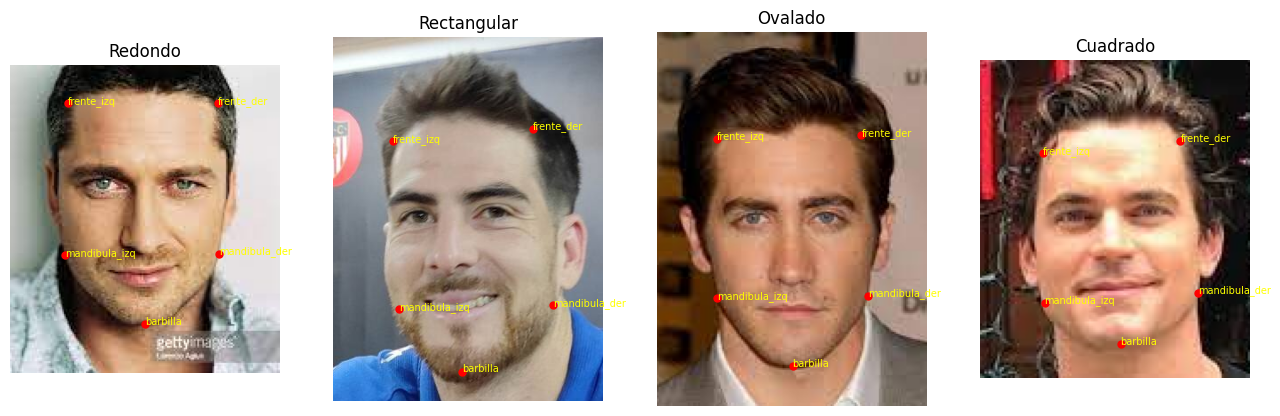

In [6]:
def recortar_rostro(imagen, caja, lados=0.3, arriba=0.5, abajo=0.2):
    x, y, ancho, alto = caja
    x1 = max(0, int(x - lados * ancho))
    x2 = min(imagen.width, int(x + ancho + lados * ancho))
    y1 = max(0, int(y - arriba * alto))
    y2 = min(imagen.height, int(y + alto + abajo * alto))
    return imagen.crop((x1, y1, x2, y2))

plt.figure(figsize=(16, 5))
for i, nombre in enumerate(clases):
    carpeta = os.path.join(RUTA_TRAIN, nombre)
    archivos = [f for f in os.listdir(carpeta) if f.lower().endswith(extensiones)]
    elegido = random.choice(archivos)
    imagen = Image.open(os.path.join(carpeta, elegido)).convert('RGB')
    resultados = detector.detect_faces(np.array(imagen))

    plt.subplot(1, 4, i + 1)
    plt.axis('off')
    if len(resultados) == 0:
        plt.title(nombre + ': MTCNN no encontró rostro')
        continue

    mejor = max(resultados, key=lambda r: r['confidence'])
    cara = recortar_rostro(imagen, mejor['box'])
    puntos = obtener_puntos(cara)
    plt.imshow(cara)
    if puntos is None:
        plt.title(nombre + ': sin puntos')
        continue

    for etiqueta, (px, py) in puntos.items():
        plt.scatter(px, py, s=25, c='red')
        plt.text(px, py, etiqueta, color='yellow', fontsize=7)
    plt.title(nombre)
plt.show()

---
## 3. Ajuste de los datos (recorte del rostro)

Se usan los 5 puntos para encuadrar cada rostro y dejarlo en el mismo formato: cuadrado de 160×160, que es el tamaño que pide FaceNet. El recorte se completa con bordes grises, **sin estirar la imagen**, porque la proporción entre ancho y alto es justo lo que distingue las formas de rostro.

### 3.1 Recorte basado en los 5 puntos

`caja_desde_puntos` arma el cuadro del recorte: de izquierda a derecha, entre el punto más a la izquierda y el más a la derecha; de arriba a abajo, desde la frente hasta la barbilla, con un margen en cada lado. `procesar_imagen` junta todo el flujo y devuelve el rostro recortado junto con un estado: `con_puntos` (caso ideal), `sin_puntos` (MTCNN encontró el rostro pero MediaPipe no) o `sin_rostro`. La fila de arriba de la figura es la foto original y la de abajo, el recorte.

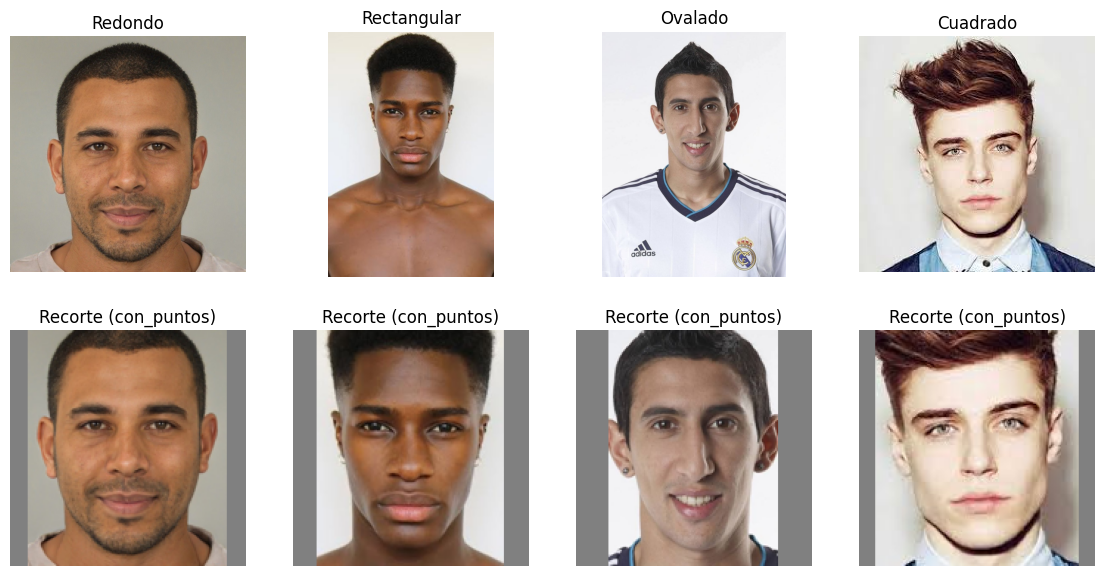

In [7]:
from PIL import ImageOps

TAM = 160
MARGEN_LADOS = 0.25
MARGEN_ARRIBA = 0.15
MARGEN_ABAJO = 0.10

def caja_desde_puntos(puntos, ancho_img, alto_img):
    xs = [p[0] for p in puntos.values()]
    x_min, x_max = min(xs), max(xs)
    y_frente = (puntos['frente_izq'][1] + puntos['frente_der'][1]) / 2
    y_barbilla = puntos['barbilla'][1]
    ancho = x_max - x_min
    alto = y_barbilla - y_frente
    x1 = max(0, int(x_min - MARGEN_LADOS * ancho))
    x2 = min(ancho_img, int(x_max + MARGEN_LADOS * ancho))
    y1 = max(0, int(y_frente - MARGEN_ARRIBA * alto))
    y2 = min(alto_img, int(y_barbilla + MARGEN_ABAJO * alto))
    return x1, y1, x2, y2

def procesar_imagen(imagen):
    resultados = detector.detect_faces(np.array(imagen))
    if len(resultados) == 0:
        return None, 'sin_rostro'

    mejor = max(resultados, key=lambda r: r['box'][2] * r['box'][3])
    cara = recortar_rostro(imagen, mejor['box'])
    puntos = obtener_puntos(cara)

    if puntos is None:
        return ImageOps.pad(cara, (TAM, TAM), color=(128, 128, 128)), 'sin_puntos'

    x1, y1, x2, y2 = caja_desde_puntos(puntos, cara.width, cara.height)
    cara = cara.crop((x1, y1, x2, y2))
    return ImageOps.pad(cara, (TAM, TAM), color=(128, 128, 128)), 'con_puntos'

plt.figure(figsize=(14, 7))
for i, nombre in enumerate(clases):
    carpeta = os.path.join(RUTA_TRAIN, nombre)
    archivos = [f for f in os.listdir(carpeta) if f.lower().endswith(extensiones)]
    elegido = random.choice(archivos)
    imagen = Image.open(os.path.join(carpeta, elegido)).convert('RGB')
    cara, estado = procesar_imagen(imagen)

    plt.subplot(2, 4, i + 1)
    plt.imshow(imagen)
    plt.title(nombre)
    plt.axis('off')

    plt.subplot(2, 4, i + 5)
    if cara is not None:
        plt.imshow(cara)
    plt.title('Recorte (' + estado + ')')
    plt.axis('off')
plt.show()

### 3.2 Recortar y guardar el conjunto Train

Recorre todas las imágenes de `Train`, las recorta y guarda el resultado en una carpeta nueva de Drive (las originales no se tocan). Si no se detecta rostro, la imagen se descarta.

**Resultado:** 1269 de 1270 imágenes con los 5 puntos y 1 descartada por no detectarse rostro.

In [8]:
from tqdm import tqdm

RUTA_BASE = '/content/drive/MyDrive/Proyecto IA II/Dataset - Rostros Masculinos'
RUTA_SALIDA_TRAIN = RUTA_BASE + '/rostros_mtcnn_train'
RUTA_SALIDA_TEST = RUTA_BASE + '/rostros_mtcnn_test'

def procesar_carpeta(ruta_origen, ruta_salida, es_test):
    resumen = {'con_puntos': 0, 'sin_puntos': 0, 'sin_rostro': 0}
    for nombre in clases:
        os.makedirs(os.path.join(ruta_salida, nombre), exist_ok=True)
        carpeta = os.path.join(ruta_origen, nombre)
        archivos = [f for f in os.listdir(carpeta) if f.lower().endswith(extensiones)]

        for archivo in tqdm(archivos, desc=nombre):
            try:
                imagen = Image.open(os.path.join(carpeta, archivo)).convert('RGB')
                cara, estado = procesar_imagen(imagen)
                resumen[estado] += 1

                if cara is None:
                    if not es_test:
                        continue
                    cara = ImageOps.pad(imagen, (TAM, TAM), color=(128, 128, 128))

                nombre_salida = os.path.splitext(archivo)[0] + '.jpg'
                cara.save(os.path.join(ruta_salida, nombre, nombre_salida))
            except Exception:
                resumen['sin_rostro'] += 1
    return resumen

resumen_train = procesar_carpeta(RUTA_TRAIN, RUTA_SALIDA_TRAIN, False)
print()
print('Train:', resumen_train)

Cuadrado: 100%|██████████| 323/323 [06:24<00:00,  1.19s/it]


Train: {'con_puntos': 1269, 'sin_puntos': 0, 'sin_rostro': 1}


### 3.3 Recortar y guardar el conjunto Test

Mismo proceso para `Test`, con una diferencia: ahí **no se descarta ninguna imagen**. Si no se detecta rostro, se usa la foto completa, para evaluar con todas las imágenes de prueba.

**Resultado:** las 323 imágenes se recortaron con los 5 puntos.

In [9]:
resumen_test = procesar_carpeta(RUTA_TEST, RUTA_SALIDA_TEST, True)
print()
print('Test:', resumen_test)

Cuadrado: 100%|██████████| 78/78 [03:00<00:00,  2.31s/it]


Test: {'con_puntos': 323, 'sin_puntos': 0, 'sin_rostro': 0}


---
## 4. Preparación de los datos para el entrenamiento

### 4.1 Instalar facenet-pytorch

Instala la librería que trae FaceNet (`InceptionResnetV1`) ya entrenada con VGGFace2. El `--no-deps` evita que cambie las versiones de PyTorch que trae Colab. Esta parte del proyecto usa PyTorch, a diferencia del modelo Inception v3, que se hizo en Keras.

In [10]:
!pip install facenet-pytorch --no-deps -q

### 4.2 Dividir Train en entrenamiento y validación

Se usan todos los rostros recortados de `Train`: **80% para entrenar y 20% para validar**. La carpeta `Test` se mantiene aparte para la evaluación final. `stratify` mantiene la proporción de clases en ambos grupos y `random_state=42` hace la división reproducible. Las etiquetas son números según el orden de `clases` (0 = Redondo, 1 = Rectangular, 2 = Ovalado, 3 = Cuadrado).

**Resultado:** 1014 imágenes de entrenamiento, 254 de validación y 323 de prueba.

In [11]:
from sklearn.model_selection import train_test_split

rutas = []
etiquetas = []
for indice, nombre in enumerate(clases):
    carpeta = os.path.join(RUTA_SALIDA_TRAIN, nombre)
    for archivo in sorted(os.listdir(carpeta)):
        if archivo.lower().endswith(extensiones):
            rutas.append(os.path.join(carpeta, archivo))
            etiquetas.append(indice)

rutas_train, rutas_val, y_train, y_val = train_test_split(
    rutas, etiquetas, test_size=0.20, stratify=etiquetas, random_state=42)

rutas_test = []
y_test = []
for indice, nombre in enumerate(clases):
    carpeta = os.path.join(RUTA_SALIDA_TEST, nombre)
    for archivo in sorted(os.listdir(carpeta)):
        if archivo.lower().endswith(extensiones):
            rutas_test.append(os.path.join(carpeta, archivo))
            y_test.append(indice)

print('Entrenamiento:', len(rutas_train))
print('Validación:', len(rutas_val))
print('Test:', len(rutas_test))

Entrenamiento: 1014
Validación: 254
Test: 323


### 4.3 Cargadores de datos y aumento de datos

- **Aumento de datos** (solo en entrenamiento): volteo horizontal, giro de hasta 8°, zoom entre 90% y 110% (relleno gris) y **cambios suaves de brillo, contraste y saturación** (nuevo). Son cambios suaves para no alterar la forma del rostro.
- `Normalize` pasa los píxeles a la escala -1 a 1, que es la que usó FaceNet al entrenarse.
- Las imágenes se cargan en memoria **una sola vez** (`imagenes_cache`) para poder repetir la división Train/Val con varias semillas sin volver a leer el disco.
- `crear_cargadores(semilla)` hace una división 80/20 distinta para cada semilla; el ensamble de la sección 6 usa tres.

In [12]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

normalizar = transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])

transformacion_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=8, scale=(0.9, 1.1), fill=128),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    normalizar])

transformacion_eval = transforms.Compose([
    transforms.ToTensor(),
    normalizar])

imagenes_cache = {}
for ruta in rutas + rutas_test:
    imagenes_cache[ruta] = Image.open(ruta).convert('RGB')

class RostrosDataset(Dataset):
    def __init__(self, rutas, etiquetas, transformacion):
        self.rutas = rutas
        self.etiquetas = etiquetas
        self.transformacion = transformacion

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, i):
        return self.transformacion(imagenes_cache[self.rutas[i]]), self.etiquetas[i]

def crear_cargadores(semilla):
    r_train, r_val, y_tr, y_va = train_test_split(
        rutas, etiquetas, test_size=0.20, stratify=etiquetas, random_state=semilla)
    d_train = RostrosDataset(r_train, y_tr, transformacion_train)
    d_val = RostrosDataset(r_val, y_va, transformacion_eval)
    c_train = DataLoader(d_train, batch_size=32, shuffle=True)
    c_val = DataLoader(d_val, batch_size=32)
    return d_train, d_val, c_train, c_val

datos_test = RostrosDataset(rutas_test, y_test, transformacion_eval)
cargador_test = DataLoader(datos_test, batch_size=32)

print('Imágenes en memoria:', len(imagenes_cache))
print('Test:', len(datos_test))

Imágenes en memoria: 1591
Test: 323


---
## 5. Modelo

### 5.1 FaceNet y funciones de pérdida

- **FaceNet** (`InceptionResnetV1`, preentrenada con VGGFace2) convierte cada rostro en un *embedding*: un vector de 512 números **de norma 1** que resume sus rasgos. Sobre él se agrega una capa `Linear` de 4 salidas, una por forma de rostro.
- Se usan **dos pérdidas a la vez**: `CrossEntropyLoss` (Softmax) con *label smoothing* de 0.1, y `CenterLoss`, que acerca el embedding de cada imagen al centro de su clase (`LAMBDA = 0.01`).
- **Ajuste 1:** los centros arrancan cerca de cero (`0.01 * randn`) y no con `randn`, porque los embeddings tienen norma 1 y con centros de norma ≈ 22 la Center Loss no servía de nada al inicio.
- **Ajuste 2:** el embedding se multiplica por `ESCALA = 10` antes de la capa final. Con norma 1 los logits son muy pequeños y el Softmax queda indeciso.
- **Ajuste 3:** la red FaceNet aprende despacio (`2e-5`) para no perder lo que ya sabe, y la capa nueva aprende rápido (`1e-3`). Se agrega `weight decay` y un programador de tasa de aprendizaje con forma de coseno (se crea dentro de la función de entrenamiento).

In [13]:
import torch.nn as nn
from facenet_pytorch import InceptionResnetV1

dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', dispositivo)

NUM_CLASES = 4
DIM_EMB = 512
LAMBDA = 0.01
ESCALA = 10
EPOCAS = 25
PACIENCIA = 8
LR_BASE = 2e-5
LR_CAPA = 1e-3
DECAIMIENTO = 1e-4
SUAVIZADO = 0.1
SEMILLAS = [1, 2, 3]
RUTA_MODELO = '/content/drive/MyDrive/Proyecto IA II/mejor_facenet_v2_semilla'

class FaceNetClasificador(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = InceptionResnetV1(pretrained='vggface2')
        self.capa_final = nn.Linear(DIM_EMB, NUM_CLASES)

    def forward(self, x):
        embedding = self.base(x)
        return embedding, self.capa_final(embedding * ESCALA)

class CenterLoss(nn.Module):
    def __init__(self, num_clases, dim):
        super().__init__()
        self.centros = nn.Parameter(0.01 * torch.randn(num_clases, dim))

    def forward(self, embedding, etiquetas):
        centros_lote = self.centros[etiquetas]
        return ((embedding - centros_lote) ** 2).sum(dim=1).mean() / 2

def cargar_modelo(semilla):
    m = FaceNetClasificador().to(dispositivo)
    m.load_state_dict(torch.load(RUTA_MODELO + str(semilla) + '.pt', map_location=dispositivo))
    m.eval()
    return m

Dispositivo: cuda


---
## 6. Entrenamiento

Se entrena un modelo por cada semilla de `SEMILLAS` (3 modelos). Cada uno usa una división Train/Val distinta, así que entre los tres ven casi todas las imágenes de entrenamiento.

En cada época la red recorre los lotes de entrenamiento, calcula la pérdida total (clasificación + Center Loss), la propaga hacia atrás y ajusta los pesos. Después mide en validación el accuracy y la **pérdida**, y **guarda en Drive el modelo con menor pérdida de validación** (la pérdida es menos ruidosa que el accuracy con solo 254 imágenes). Si la pérdida de validación no mejora en `PACIENCIA` épocas seguidas, el entrenamiento se detiene.

`Test` no se usa en ningún momento del entrenamiento.

In [14]:
def entrenar(semilla):
    torch.manual_seed(semilla)
    np.random.seed(semilla)
    random.seed(semilla)

    datos_train, datos_val, cargador_train, cargador_val = crear_cargadores(semilla)

    modelo = FaceNetClasificador().to(dispositivo)
    perdida_centros = CenterLoss(NUM_CLASES, DIM_EMB).to(dispositivo)
    perdida_clasificacion = nn.CrossEntropyLoss(label_smoothing=SUAVIZADO)
    perdida_validacion = nn.CrossEntropyLoss(reduction='sum')

    optimizador_modelo = torch.optim.AdamW([
        {'params': modelo.base.parameters(), 'lr': LR_BASE},
        {'params': modelo.capa_final.parameters(), 'lr': LR_CAPA}],
        weight_decay=DECAIMIENTO)
    optimizador_centros = torch.optim.SGD(perdida_centros.parameters(), lr=0.5)
    programador = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador_modelo, T_max=EPOCAS)

    mejor_perdida_val = 1e9
    sin_mejora = 0
    historial = []

    for epoca in range(1, EPOCAS + 1):
        modelo.train()
        perdida_total = 0
        correctos_train = 0

        for imagenes, etiquetas in cargador_train:
            imagenes = imagenes.to(dispositivo)
            etiquetas = etiquetas.to(dispositivo)

            embedding, salidas = modelo(imagenes)
            perdida = perdida_clasificacion(salidas, etiquetas) + LAMBDA * perdida_centros(embedding, etiquetas)

            optimizador_modelo.zero_grad()
            optimizador_centros.zero_grad()
            perdida.backward()
            for parametro in perdida_centros.parameters():
                parametro.grad.data *= (1.0 / LAMBDA)
            optimizador_modelo.step()
            optimizador_centros.step()

            perdida_total += perdida.item() * etiquetas.size(0)
            correctos_train += (salidas.argmax(dim=1) == etiquetas).sum().item()

        programador.step()

        modelo.eval()
        correctos_val = 0
        suma_perdida_val = 0
        with torch.no_grad():
            for imagenes, etiquetas in cargador_val:
                imagenes = imagenes.to(dispositivo)
                etiquetas = etiquetas.to(dispositivo)
                _, salidas = modelo(imagenes)
                correctos_val += (salidas.argmax(dim=1) == etiquetas).sum().item()
                suma_perdida_val += perdida_validacion(salidas, etiquetas).item()

        loss_train = perdida_total / len(datos_train)
        acc_train = correctos_train / len(datos_train)
        acc_val = correctos_val / len(datos_val)
        loss_val = suma_perdida_val / len(datos_val)
        historial.append((loss_train, acc_train, acc_val, loss_val))
        print(f'Época {epoca:2d} | loss {loss_train:.4f} | train {acc_train:.3f} | val {acc_val:.3f} | loss val {loss_val:.4f}')

        if loss_val < mejor_perdida_val:
            mejor_perdida_val = loss_val
            sin_mejora = 0
            torch.save(modelo.state_dict(), RUTA_MODELO + str(semilla) + '.pt')
            mejor_epoca = epoca
            mejor_acc_val = acc_val
        else:
            sin_mejora += 1
            if sin_mejora >= PACIENCIA:
                print('Parada anticipada en la época', epoca)
                break

    print('Mejor época:', mejor_epoca, '| accuracy en validación:', round(mejor_acc_val, 4))
    return historial

historiales = {}
for semilla in SEMILLAS:
    print()
    print('===== Modelo con semilla', semilla, '=====')
    historiales[semilla] = entrenar(semilla)


===== Modelo con semilla 1 =====


  0%|          | 0.00/107M [00:00<?, ?B/s]

Época  1 | loss 0.8999 | train 0.724 | val 0.866 | loss val 0.4574
Época  2 | loss 0.5544 | train 0.906 | val 0.906 | loss val 0.3307
Época  3 | loss 0.4884 | train 0.948 | val 0.909 | loss val 0.2886
Época  4 | loss 0.4491 | train 0.966 | val 0.933 | loss val 0.2623
Época  5 | loss 0.4135 | train 0.981 | val 0.933 | loss val 0.2620
Época  6 | loss 0.4087 | train 0.985 | val 0.933 | loss val 0.2684
Época  7 | loss 0.3967 | train 0.989 | val 0.937 | loss val 0.2453
Época  8 | loss 0.3976 | train 0.991 | val 0.937 | loss val 0.2506
Época  9 | loss 0.3882 | train 0.993 | val 0.941 | loss val 0.2499
Época 10 | loss 0.3871 | train 0.994 | val 0.941 | loss val 0.2547
Época 11 | loss 0.3773 | train 0.994 | val 0.941 | loss val 0.2447
Época 12 | loss 0.3771 | train 0.993 | val 0.937 | loss val 0.2549
Época 13 | loss 0.3767 | train 0.994 | val 0.933 | loss val 0.2575
Época 14 | loss 0.3730 | train 0.996 | val 0.937 | loss val 0.2470
Época 15 | loss 0.3683 | train 0.998 | val 0.937 | loss val 0.

---
## 7. Resultados

### 7.1 Curvas de entrenamiento

Precisión de entrenamiento y de validación, y pérdida de validación, por época y para cada uno de los 3 modelos. La validación es solo el 20% de `Train` (254 imágenes), así que cada punto de la curva es ruidoso.

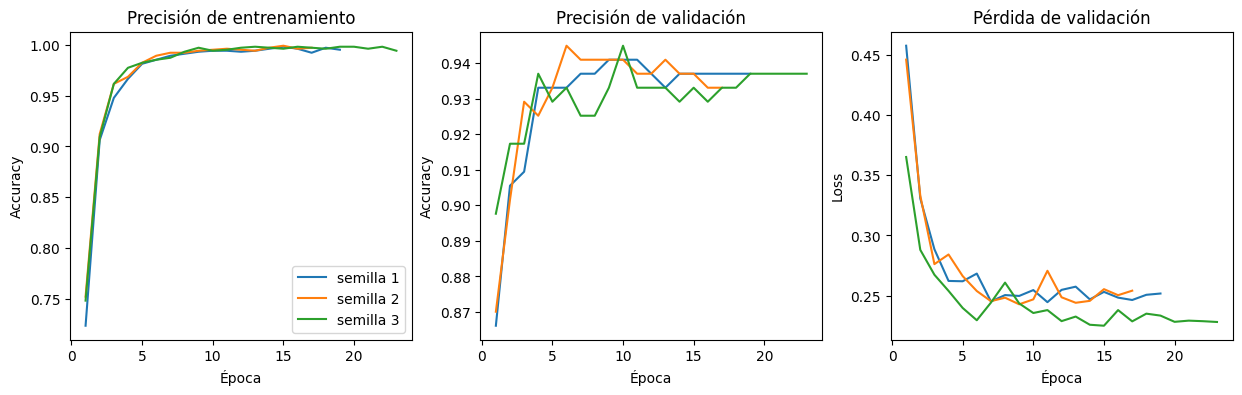

In [15]:
plt.figure(figsize=(15, 4))

for semilla in SEMILLAS:
    valores = np.array(historiales[semilla])
    epocas = np.arange(1, len(valores) + 1)

    plt.subplot(1, 3, 1)
    plt.plot(epocas, valores[:, 1], label='semilla ' + str(semilla))
    plt.subplot(1, 3, 2)
    plt.plot(epocas, valores[:, 2], label='semilla ' + str(semilla))
    plt.subplot(1, 3, 3)
    plt.plot(epocas, valores[:, 3], label='semilla ' + str(semilla))

plt.subplot(1, 3, 1)
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.title('Precisión de entrenamiento')
plt.legend()

plt.subplot(1, 3, 2)
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.title('Precisión de validación')

plt.subplot(1, 3, 3)
plt.xlabel('Época')
plt.ylabel('Loss')
plt.title('Pérdida de validación')
plt.show()

### 7.2 Evaluación en Test

Carga los **3 mejores modelos guardados** y mide su accuracy sobre `Test`, de tres formas:

- cada modelo solo,
- cada modelo con **test-time augmentation** (se predice la imagen normal y volteada, y se promedian las probabilidades),
- el **ensamble** de los 3 modelos con volteo (promedio de las probabilidades). **Esta es la cifra de referencia del método.**

Para comparar: la versión anterior (un solo modelo, sin volteo) dio **0.709**.

In [25]:
def probabilidades_modelo(modelo, cargador, con_volteo):
    modelo.eval()
    lista = []
    with torch.no_grad():
        for imagenes, _ in cargador:
            imagenes = imagenes.to(dispositivo)
            _, salidas = modelo(imagenes)
            p = torch.softmax(salidas, dim=1)
            if con_volteo:
                _, salidas_v = modelo(torch.flip(imagenes, dims=[3]))
                p = (p + torch.softmax(salidas_v, dim=1)) / 2
            lista.append(p.cpu().numpy())
    return np.concatenate(lista)

modelos = [cargar_modelo(s) for s in SEMILLAS]
y_real = list(y_test)

def accuracy(probs):
    pred = probs.argmax(axis=1).tolist()
    return sum([1 for real, p in zip(y_real, pred) if real == p]) / len(y_real)

probs_con_volteo = []
for semilla, m in zip(SEMILLAS, modelos):
    p_normal = probabilidades_modelo(m, cargador_test, False)
    p_volteo = probabilidades_modelo(m, cargador_test, True)
    probs_con_volteo.append(p_volteo)
    print('Semilla', semilla, '| sin volteo:', round(accuracy(p_normal), 4), '| con volteo:', round(accuracy(p_volteo), 4))

prob_final = np.mean(probs_con_volteo, axis=0)
y_pred = prob_final.argmax(axis=1).tolist()

print()
print('Imágenes evaluadas:', len(y_real))
print('Accuracy en Test (ensamble de 3 modelos + volteo):', round(accuracy(prob_final), 4))

Semilla 1 | sin volteo: 0.7028 | con volteo: 0.6966
Semilla 2 | sin volteo: 0.6904 | con volteo: 0.6873
Semilla 3 | sin volteo: 0.7028 | con volteo: 0.7121

Imágenes evaluadas: 323
Accuracy en Test (ensamble de 3 modelos + volteo): 0.6997


### 7.3 Matriz de confusión y reporte por clase

El reporte da precisión (de las que predijo como X, cuántas lo eran), recall (de las X reales, cuántas encontró) y f1-score por clase. Se calculan con las predicciones del ensamble.

              precision    recall  f1-score   support

     Redondo      0.793     0.783     0.788        83
 Rectangular      0.577     0.691     0.629        81
     Ovalado      0.637     0.630     0.634        81
    Cuadrado      0.844     0.692     0.761        78

    accuracy                          0.700       323
   macro avg      0.713     0.699     0.703       323
weighted avg      0.712     0.700     0.703       323



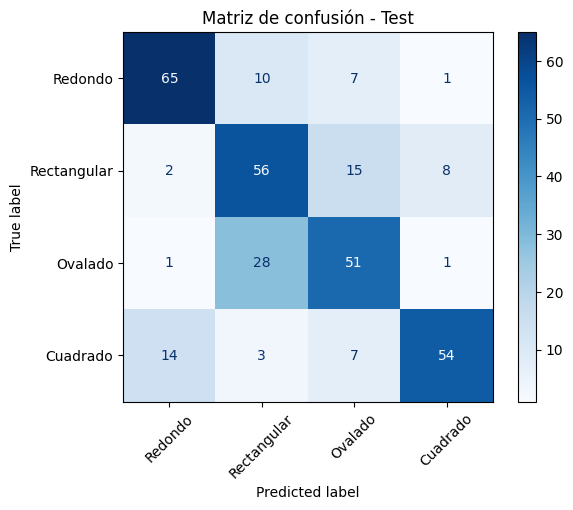

In [17]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

print(classification_report(y_real, y_pred, target_names=clases, digits=3))

matriz = confusion_matrix(y_real, y_pred)
ConfusionMatrixDisplay(matriz, display_labels=clases).plot(cmap='Blues', xticks_rotation=45)
plt.title('Matriz de confusión - Test')
plt.show()

---
## 8. Prueba con fotos de clientes

Se prueba el flujo completo con las fotos de la carpeta `Clientes`, que **no pertenecen al dataset**: MTCNN detecta el rostro, se recorta con los 5 puntos y el ensamble de 3 modelos FaceNet (con volteo) lo clasifica. Para cada foto se muestra la predicción con su confianza (la probabilidad de la clase elegida) y si fue acierto o error, comparando con la clase real, que se toma del **nombre del archivo** (`redondo.jpg` se interpreta como Redondo). Al final se calcula el accuracy sobre todas las fotos. Con tan pocas fotos el accuracy solo toma valores como 0%, 25%, 50%, 75% o 100%, así que sirve como demostración y no como medida de calidad.

Ajusta `RUTA_CLIENTES` a la carpeta donde estén las fotos.

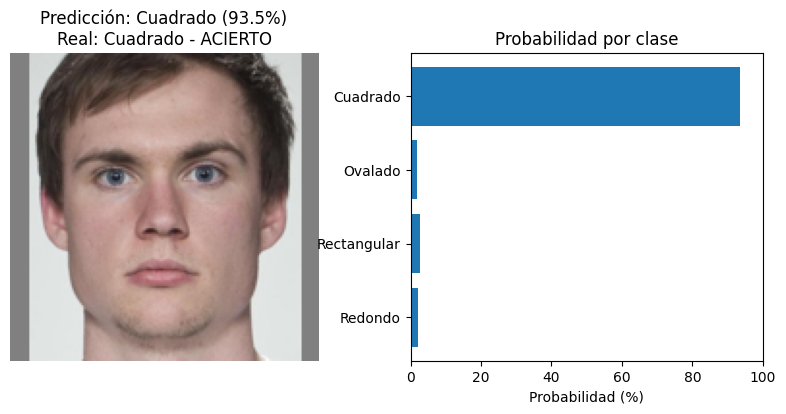

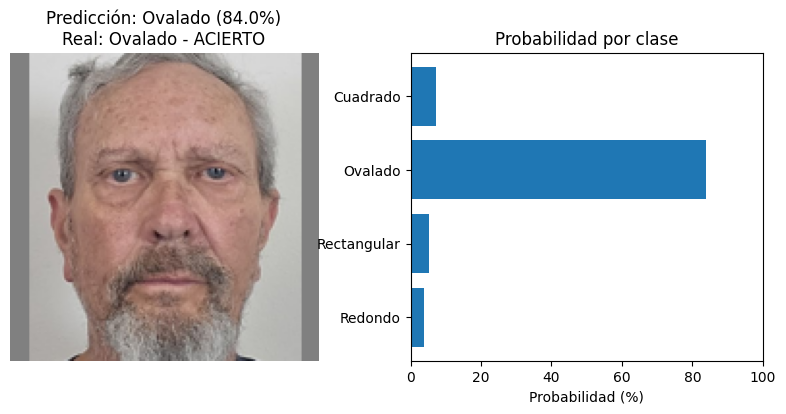

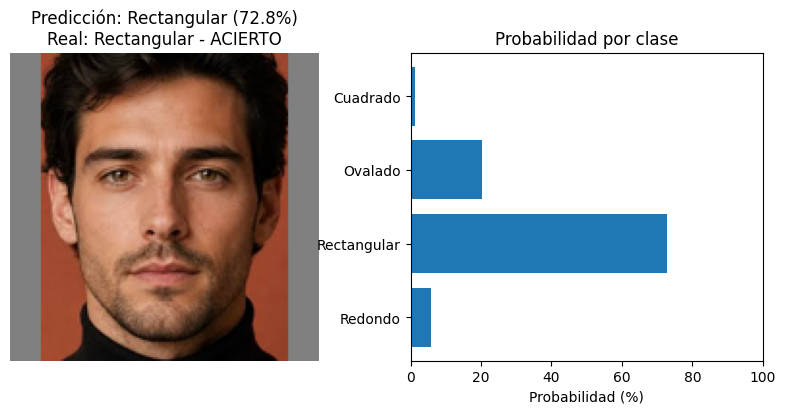

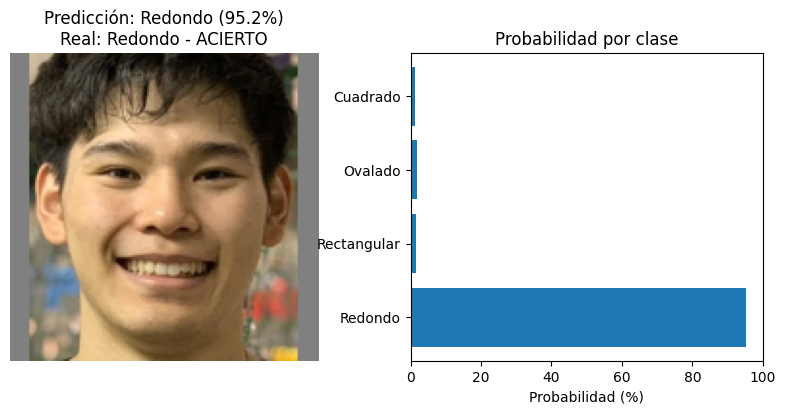

Fotos de clientes evaluadas: 4
Aciertos: 4
Accuracy en fotos de clientes: 100.0 %


In [19]:
RUTA_CLIENTES = '/content/drive/MyDrive/Proyecto IA II/Clientes'

def predecir_cliente(ruta_foto, clase_real=None):
    imagen = Image.open(ruta_foto).convert('RGB')
    cara, estado = procesar_imagen(imagen)

    if cara is None:
        print('No se detectó ningún rostro en la foto')
        return None

    entrada = transformacion_eval(cara).unsqueeze(0).to(dispositivo)
    lista_probs = []
    with torch.no_grad():
        for m in modelos:
            m.eval()
            _, salidas = m(entrada)
            _, salidas_v = m(torch.flip(entrada, dims=[3]))
            lista_probs.append((torch.softmax(salidas, dim=1) + torch.softmax(salidas_v, dim=1))[0].cpu().numpy() / 2)
    probabilidades = np.mean(lista_probs, axis=0)

    mejor = int(np.argmax(probabilidades))
    predicha = clases[mejor]
    confianza = probabilidades[mejor] * 100

    titulo = 'Predicción: ' + predicha + ' (' + str(round(confianza, 1)) + '%)'
    if clase_real is not None:
        if predicha == clase_real:
            titulo = titulo + '\nReal: ' + clase_real + ' - ACIERTO'
        else:
            titulo = titulo + '\nReal: ' + clase_real + ' - ERROR'

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(cara)
    plt.title(titulo)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.barh(clases, probabilidades * 100)
    plt.xlim(0, 100)
    plt.xlabel('Probabilidad (%)')
    plt.title('Probabilidad por clase')
    plt.show()

    return predicha

archivos_clientes = sorted([f for f in os.listdir(RUTA_CLIENTES) if f.lower().endswith(extensiones)])

aciertos_clientes = 0
evaluadas = 0
for archivo in archivos_clientes:
    nombre = os.path.splitext(archivo)[0].capitalize()
    clase_real = nombre if nombre in clases else None
    predicha = predecir_cliente(os.path.join(RUTA_CLIENTES, archivo), clase_real)
    if predicha is not None and clase_real is not None:
        evaluadas += 1
        if predicha == clase_real:
            aciertos_clientes += 1

print('Fotos de clientes evaluadas:', evaluadas)
print('Aciertos:', aciertos_clientes)
if evaluadas > 0:
    print('Accuracy en fotos de clientes:', round(100 * aciertos_clientes / evaluadas, 1), '%')

---
## 10. Motor de reglas: recomendación de cortes

A partir de la forma de rostro predicha, el motor recomienda **1 o 2 cortes**, un **largo superior** (corto, medio o largo) y un **ranking de 3 degradados**.

**Separamos tres decisiones**, porque en barbería son cosas distintas:

- **Corte:** el estilo de la parte superior (Pompadour, Side part, French crop...).
- **Largo superior:** corto (1-3 cm), medio (4-6 cm) o largo (7 cm o más). Son rangos aproximados.
- **Degradado:** cómo bajan los laterales (Low fade, Mid fade, Low taper...). Por eso *Low fade*, *Mid fade* y *Low taper* están en el ranking de degradados y no en la lista de cortes.

**Principios de las reglas** (de guías de barberos, ver la nota al final de la sección):

- **Redondo:** dar altura arriba y laterales cortos, para alargar. Evitar flequillo recto y volumen a los lados.
- **Ovalado:** proporciones equilibradas, casi cualquier estilo funciona.
- **Cuadrado:** suavizar los ángulos con estilos asimétricos (raya lateral) y longitud arriba. Evitar laterales muy "cuadrados".
- **Rectangular:** ensanchar y no sumar altura. Largo corto o medio, laterales medios (no a piel) y textura o flequillo.

**Cuándo da 1 y cuándo 2 cortes:** si la confianza de la forma predicha es mayor o igual a `UMBRAL_CONFIANZA`, recomienda 1 corte. Si es menor, hay duda entre dos formas (típicamente Ovalado y Rectangular), y el segundo corte se elige **de modo que sirva también para la segunda forma más probable** cuando existe uno compartido.

**Nivel de respaldo** de cada corte: `alto` (lo recomiendan varias fuentes para esa forma), `medio` (lo respalda una fuente o depende de cómo se ejecute). Las reglas son una base para validar con tu barbero, no una verdad absoluta.

In [20]:
# ---------- Catálogo de cortes (estilo superior) ----------
ORDEN_LARGO = ['corto', 'medio', 'largo']

CORTES = {
    'Pompadour':      {'largo': 'largo', 'descripcion': 'Volumen alto peinado hacia arriba y atrás, laterales cortos.'},
    'Undercut':       {'largo': 'largo', 'descripcion': 'Laterales y nuca muy cortos con mucho contraste frente a la parte de arriba.'},
    'Mod cut':        {'largo': 'medio', 'descripcion': 'Parte superior media y con forma; ideal peinada hacia arriba, no con flequillo recto.'},
    'French crop':    {'largo': 'corto', 'descripcion': 'Corto y texturizado, con flequillo corto hacia adelante.'},
    'Quiff':          {'largo': 'medio', 'descripcion': 'Frente levantada con volumen y textura.'},
    'Side part':      {'largo': 'medio', 'descripcion': 'Raya lateral clásica; la línea diagonal rompe la simetría del rostro.'},
    'Slick back':     {'largo': 'largo', 'descripcion': 'Peinado hacia atrás, mejor suave y con laterales no demasiado cortos.'},
    'Textured fringe': {'largo': 'medio', 'descripcion': 'Flequillo texturizado que cae sobre la frente.'},
    'Crew cut':       {'largo': 'corto', 'descripcion': 'Muy corto arriba, uniforme y de bajo mantenimiento.'},
}

# ---------- Catálogo de degradados (laterales) ----------
DEGRADADOS = {
    'High fade':    'Transición alta, sobre las sienes; contraste fuerte con la parte de arriba.',
    'Mid fade':     'Transición a media altura de la cabeza; equilibrado.',
    'Low fade':     'Transición baja, cerca de la oreja y la nuca; discreto.',
    'Skin fade':    'Se rapa hasta la piel en la base; el contraste más marcado.',
    'Low taper':    'Reducción gradual y suave en patillas y nuca, sin llegar a piel.',
    'Taper clásico': 'Laterales medios, a tijera o con guía alta; conserva el ancho a los lados.',
}

# ---------- Reglas por forma de rostro ----------
# cortes: de mayor a menor prioridad, con su nivel de respaldo.
REGLAS = {
    'Redondo': {
        'cortes': [('Pompadour', 'alto'), ('Undercut', 'alto'), ('Mod cut', 'medio')],
        'largos_permitidos': ['medio', 'largo'],
        'degradados': ['High fade', 'Mid fade', 'Skin fade'],
        'motivo': 'Altura arriba y laterales cortos alargan visualmente el rostro.',
        'evitar': 'Flequillo recto, laterales con volumen, melenas sin capas.',
    },
    'Rectangular': {
        'cortes': [('Side part', 'alto'), ('Textured fringe', 'alto'), ('Crew cut', 'medio')],
        'largos_permitidos': ['corto', 'medio'],
        'degradados': ['Taper clásico', 'Low taper', 'Low fade'],
        'motivo': 'Se busca ancho a los lados y poca altura arriba para acortar el rostro.',
        'evitar': 'Pompadour, quiff alto, fades altos o a piel con volumen arriba.',
    },
    'Ovalado': {
        'cortes': [('French crop', 'alto'), ('Quiff', 'alto'), ('Side part', 'alto')],
        'largos_permitidos': ['corto', 'medio', 'largo'],
        'degradados': ['Low fade', 'Mid fade', 'High fade'],
        'motivo': 'Proporciones equilibradas: admite casi cualquier estilo.',
        'evitar': 'Flequillo muy pesado que tape la frente.',
    },
    'Cuadrado': {
        'cortes': [('Side part', 'alto'), ('Quiff', 'alto'), ('Slick back', 'medio')],
        'largos_permitidos': ['medio', 'largo'],
        'degradados': ['Low taper', 'Low fade', 'Mid fade'],
        'motivo': 'Estilos asimétricos y algo de longitud arriba suavizan los ángulos de la mandíbula.',
        'evitar': 'Laterales muy anchos y "cuadrados".',
    },
}

UMBRAL_CONFIANZA = 0.75

def ajustar_largo(largo_corte, permitidos):
    if largo_corte in permitidos:
        return largo_corte
    pos = ORDEN_LARGO.index(largo_corte)
    mejor = permitidos[0]
    for p in permitidos:
        if abs(ORDEN_LARGO.index(p) - pos) < abs(ORDEN_LARGO.index(mejor) - pos):
            mejor = p
    return mejor

def recomendar(probs):
    orden = np.argsort(probs)[::-1]
    forma = clases[orden[0]]
    forma_2 = clases[orden[1]]
    confianza = float(probs[orden[0]])
    regla = REGLAS[forma]
    lista_1 = [c for c, _ in regla['cortes']]

    elegidos = [lista_1[0]]
    if confianza < UMBRAL_CONFIANZA:
        lista_2 = [c for c, _ in REGLAS[forma_2]['cortes']]
        compartidos = [c for c in lista_1 if c in lista_2 and c not in elegidos]
        if len(compartidos) > 0:
            elegidos.append(compartidos[0])
        else:
            elegidos.append(lista_1[1])

    respaldo = dict(regla['cortes'])
    cortes = []
    for nombre in elegidos:
        cortes.append({
            'nombre': nombre,
            'largo': ajustar_largo(CORTES[nombre]['largo'], regla['largos_permitidos']),
            'respaldo': respaldo[nombre],
            'descripcion': CORTES[nombre]['descripcion']})

    return {'forma': forma, 'confianza': confianza, 'forma_alterna': forma_2,
            'cortes': cortes, 'degradados': regla['degradados'],
            'motivo': regla['motivo'], 'evitar': regla['evitar']}

def mostrar_recomendacion(rec):
    print('Forma del rostro:', rec['forma'], '(' + str(round(rec['confianza'] * 100, 1)) + '%)')
    if rec['confianza'] < UMBRAL_CONFIANZA:
        print('  Hay duda con la forma', rec['forma_alterna'], '-> se sugieren 2 cortes')
    print('Por qué:', rec['motivo'])
    for i, c in enumerate(rec['cortes']):
        print('Corte', i + 1, ':', c['nombre'], '| largo arriba:', c['largo'], '| respaldo:', c['respaldo'])
        print('         ', c['descripcion'])
    print('Degradados (de mejor a peor):')
    for i, d in enumerate(rec['degradados']):
        print('  ' + str(i + 1) + '.', d, '-', DEGRADADOS[d])
    print('Evitar:', rec['evitar'])

# Demo con probabilidades inventadas (orden de clases: Redondo, Rectangular, Ovalado, Cuadrado)
print('--- Caso seguro ---')
mostrar_recomendacion(recomendar(np.array([0.05, 0.05, 0.85, 0.05])))
print()
print('--- Caso con duda Ovalado / Rectangular ---')
mostrar_recomendacion(recomendar(np.array([0.05, 0.40, 0.50, 0.05])))

--- Caso seguro ---
Forma del rostro: Ovalado (85.0%)
Por qué: Proporciones equilibradas: admite casi cualquier estilo.
Corte 1 : French crop | largo arriba: corto | respaldo: alto
          Corto y texturizado, con flequillo corto hacia adelante.
Degradados (de mejor a peor):
  1. Low fade - Transición baja, cerca de la oreja y la nuca; discreto.
  2. Mid fade - Transición a media altura de la cabeza; equilibrado.
  3. High fade - Transición alta, sobre las sienes; contraste fuerte con la parte de arriba.
Evitar: Flequillo muy pesado que tape la frente.

--- Caso con duda Ovalado / Rectangular ---
Forma del rostro: Ovalado (50.0%)
  Hay duda con la forma Rectangular -> se sugieren 2 cortes
Por qué: Proporciones equilibradas: admite casi cualquier estilo.
Corte 1 : French crop | largo arriba: corto | respaldo: alto
          Corto y texturizado, con flequillo corto hacia adelante.
Corte 2 : Side part | largo arriba: medio | respaldo: alto
          Raya lateral clásica; la línea diagon

### 10.2 Evaluación: cortes etiquetados vs cortes que recomienda el modelo

Siguiendo la recomendación del profesor, se etiqueta cada imagen de Test con los cortes que le favorecen y se compara con lo que recomienda el modelo:

- **Etiqueta de referencia:** el motor de reglas aplicado a la **forma real** de la imagen (la carpeta de donde viene). Da la lista de 3 cortes, el largo superior y el ranking de degradados "correctos".
- **Recomendación del modelo:** el mismo motor aplicado a la **forma predicha** por el ensamble, con sus 1 o 2 cortes.

**Métricas:**

- *Corte principal:* el primer corte del modelo es igual al primer corte de la etiqueta (la más estricta).
- *Algún corte válido:* al menos uno de los cortes recomendados está entre los 3 cortes etiquetados.
- *Precisión de cortes:* de los cortes recomendados, qué proporción está entre los etiquetados.
- *Largo superior:* coincide el largo del primer corte.
- *Degradado 1:* coincide el primer degradado del ranking. *Solapamiento top-3:* cuántos de los 3 degradados coinciden, sin importar el orden.

**Cómo leerla:** con esta etiqueta automática los errores de forma cuestan menos cuando las dos formas comparten cortes (por ejemplo Side part en Rectangular y Ovalado), así que estas cifras salen más altas que el accuracy de forma. Mide cuánto se propaga un error de la red hacia la recomendación, no si la recomendación le favorece de verdad a la persona; eso lo mide la sección 10.3, con la opinión del barbero.

In [21]:
def etiqueta_referencia(forma):
    regla = REGLAS[forma]
    nombres = [c for c, _ in regla['cortes']]
    return {'cortes': nombres,
            'largo': ajustar_largo(CORTES[nombres[0]]['largo'], regla['largos_permitidos']),
            'degradados': regla['degradados']}

n = len(y_real)
acierto_forma = 0
acierto_principal = 0
acierto_alguno = 0
suma_precision = 0
acierto_largo = 0
acierto_degradado_1 = 0
suma_solape = 0
una_recomendacion = 0

por_clase = {c: {'n': 0, 'principal': 0, 'alguno': 0} for c in clases}

for i in range(n):
    forma_real = clases[y_real[i]]
    ref = etiqueta_referencia(forma_real)
    rec = recomendar(prob_final[i])
    nombres_rec = [c['nombre'] for c in rec['cortes']]

    if rec['forma'] == forma_real:
        acierto_forma += 1
    if nombres_rec[0] == ref['cortes'][0]:
        acierto_principal += 1
        por_clase[forma_real]['principal'] += 1
    en_etiqueta = [c for c in nombres_rec if c in ref['cortes']]
    if len(en_etiqueta) > 0:
        acierto_alguno += 1
        por_clase[forma_real]['alguno'] += 1
    suma_precision += len(en_etiqueta) / len(nombres_rec)
    if rec['cortes'][0]['largo'] == ref['largo']:
        acierto_largo += 1
    if rec['degradados'][0] == ref['degradados'][0]:
        acierto_degradado_1 += 1
    suma_solape += len([d for d in rec['degradados'] if d in ref['degradados']]) / 3
    if len(nombres_rec) == 1:
        una_recomendacion += 1
    por_clase[forma_real]['n'] += 1

print('Imágenes evaluadas:', n)
print('Recomendaciones con 1 corte:', una_recomendacion, '| con 2 cortes:', n - una_recomendacion)
print()
print('Accuracy de la forma (referencia):      ', round(acierto_forma / n, 3))
print('Corte principal igual a la etiqueta:    ', round(acierto_principal / n, 3))
print('Algún corte recomendado es válido:      ', round(acierto_alguno / n, 3))
print('Precisión de los cortes recomendados:   ', round(suma_precision / n, 3))
print('Largo superior igual a la etiqueta:     ', round(acierto_largo / n, 3))
print('Degradado 1 igual a la etiqueta:        ', round(acierto_degradado_1 / n, 3))
print('Solapamiento top-3 de degradados:       ', round(suma_solape / n, 3))
print()
print('Por forma real (corte principal / algún corte válido):')
for c in clases:
    d = por_clase[c]
    print('  ', c.ljust(12), round(d['principal'] / d['n'], 3), '/', round(d['alguno'] / d['n'], 3), '(n =', d['n'], ')')

Imágenes evaluadas: 323
Recomendaciones con 1 corte: 171 | con 2 cortes: 152

Accuracy de la forma (referencia):       0.7
Corte principal igual a la etiqueta:     0.734
Algún corte recomendado es válido:       0.879
Precisión de los cortes recomendados:    0.8
Largo superior igual a la etiqueta:      0.734
Degradado 1 igual a la etiqueta:         0.7
Solapamiento top-3 de degradados:        0.815

Por forma real (corte principal / algún corte válido):
   Redondo      0.783 / 0.783 (n = 83 )
   Rectangular  0.79 / 0.938 (n = 81 )
   Ovalado      0.63 / 0.988 (n = 81 )
   Cuadrado     0.731 / 0.808 (n = 78 )


### 10.3 Recomendación completa para fotos de clientes

Une todo el flujo: MTCNN y los 5 puntos recortan el rostro, el ensamble de 3 FaceNet predice la forma (con volteo) y el motor de reglas recomienda los cortes, el largo superior y el ranking de degradados.

Foto: cuadrado.jpg


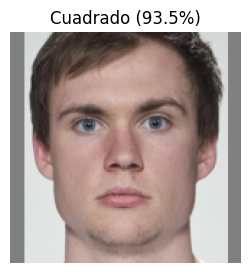

Forma del rostro: Cuadrado (93.5%)
Por qué: Estilos asimétricos y algo de longitud arriba suavizan los ángulos de la mandíbula.
Corte 1 : Side part | largo arriba: medio | respaldo: alto
          Raya lateral clásica; la línea diagonal rompe la simetría del rostro.
Degradados (de mejor a peor):
  1. Low taper - Reducción gradual y suave en patillas y nuca, sin llegar a piel.
  2. Low fade - Transición baja, cerca de la oreja y la nuca; discreto.
  3. Mid fade - Transición a media altura de la cabeza; equilibrado.
Evitar: Laterales muy anchos y "cuadrados".
Foto: ovalado.jpg


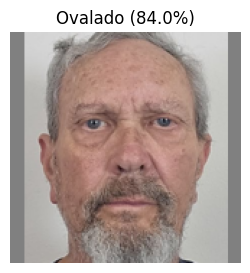

Forma del rostro: Ovalado (84.0%)
Por qué: Proporciones equilibradas: admite casi cualquier estilo.
Corte 1 : French crop | largo arriba: corto | respaldo: alto
          Corto y texturizado, con flequillo corto hacia adelante.
Degradados (de mejor a peor):
  1. Low fade - Transición baja, cerca de la oreja y la nuca; discreto.
  2. Mid fade - Transición a media altura de la cabeza; equilibrado.
  3. High fade - Transición alta, sobre las sienes; contraste fuerte con la parte de arriba.
Evitar: Flequillo muy pesado que tape la frente.
Foto: rectangular.jpg


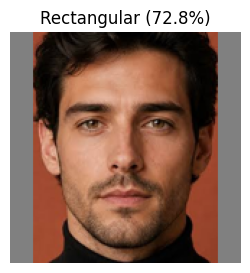

Forma del rostro: Rectangular (72.8%)
  Hay duda con la forma Ovalado -> se sugieren 2 cortes
Por qué: Se busca ancho a los lados y poca altura arriba para acortar el rostro.
Corte 1 : Side part | largo arriba: medio | respaldo: alto
          Raya lateral clásica; la línea diagonal rompe la simetría del rostro.
Corte 2 : Textured fringe | largo arriba: medio | respaldo: alto
          Flequillo texturizado que cae sobre la frente.
Degradados (de mejor a peor):
  1. Taper clásico - Laterales medios, a tijera o con guía alta; conserva el ancho a los lados.
  2. Low taper - Reducción gradual y suave en patillas y nuca, sin llegar a piel.
  3. Low fade - Transición baja, cerca de la oreja y la nuca; discreto.
Evitar: Pompadour, quiff alto, fades altos o a piel con volumen arriba.
Foto: redondo.jpg


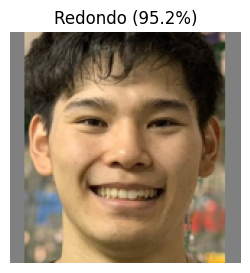

Forma del rostro: Redondo (95.2%)
Por qué: Altura arriba y laterales cortos alargan visualmente el rostro.
Corte 1 : Pompadour | largo arriba: largo | respaldo: alto
          Volumen alto peinado hacia arriba y atrás, laterales cortos.
Degradados (de mejor a peor):
  1. High fade - Transición alta, sobre las sienes; contraste fuerte con la parte de arriba.
  2. Mid fade - Transición a media altura de la cabeza; equilibrado.
  3. Skin fade - Se rapa hasta la piel en la base; el contraste más marcado.
Evitar: Flequillo recto, laterales con volumen, melenas sin capas.


In [24]:
def probabilidades_ensamble(cara):
    entrada = transformacion_eval(cara).unsqueeze(0).to(dispositivo)
    lista_probs = []
    with torch.no_grad():
        for m in modelos:
            m.eval()
            _, salidas = m(entrada)
            _, salidas_v = m(torch.flip(entrada, dims=[3]))
            lista_probs.append((torch.softmax(salidas, dim=1) + torch.softmax(salidas_v, dim=1))[0].cpu().numpy() / 2)
    return np.mean(lista_probs, axis=0)

def recomendar_cliente(ruta_foto):
    imagen = Image.open(ruta_foto).convert('RGB')
    cara, estado = procesar_imagen(imagen)
    if cara is None:
        print('No se detectó ningún rostro en la foto')
        return None
    probs = probabilidades_ensamble(cara)
    rec = recomendar(probs)

    plt.figure(figsize=(3, 3))
    plt.imshow(cara)
    plt.title(rec['forma'] + ' (' + str(round(rec['confianza'] * 100, 1)) + '%)')
    plt.axis('off')
    plt.show()
    mostrar_recomendacion(rec)
    return rec

for archivo in archivos_clientes:
    print('=' * 60)
    print('Foto:', archivo)
    recomendar_cliente(os.path.join(RUTA_CLIENTES, archivo))